<a href="https://colab.research.google.com/github/pjcarney/Alien-Signal/blob/main/Alien_Signal.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# Import the alien signal data

import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Load the alien transmission
alien_signal = pd.read_csv(
    "https://raw.githubusercontent.com/pjcarney/Alien-Signal/refs/heads/main/alien_signal.csv"
)



# Separate inputs and outputs
x = alien_signal["input"].values
y = alien_signal["output"].values

print("Transmission received!")
print("Number of data points:", len(x))

Transmission received!
Number of data points: 100


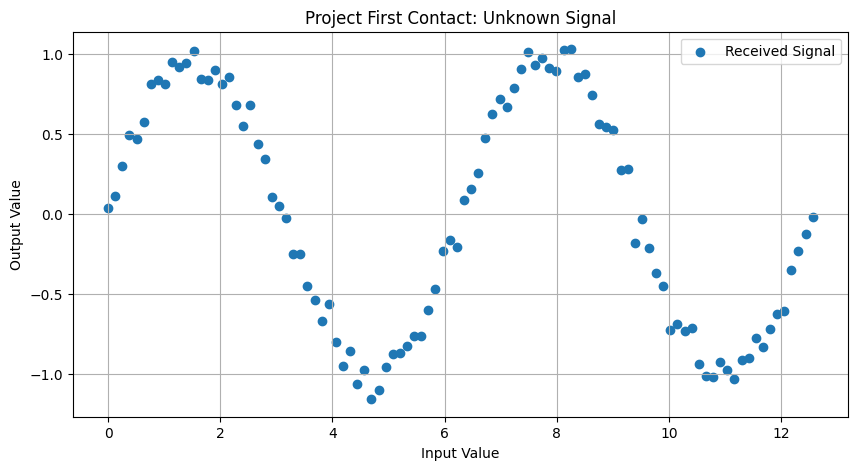

In [ ]:

import matplotlib.pyplot as plt

# Plot the received alien transmission
plt.figure(figsize=(10, 5))

plt.scatter(x, y, label="Received Signal")

plt.xlabel("Input Value")
plt.ylabel("Output Value")
plt.title("Project First Contact: Unknown Signal")

plt.legend()
plt.grid(True)
plt.show()


In [ ]:

# Initial decoder settings

weight = 0.0
bias = 0.0

# Make predictions using our initial model
predictions = weight * x + bias

# Display the first predictions
#for i in range(10):
#    print("Actual:", round(y[i], 3),
#          "Predicted:", round(predictions[i], 3))


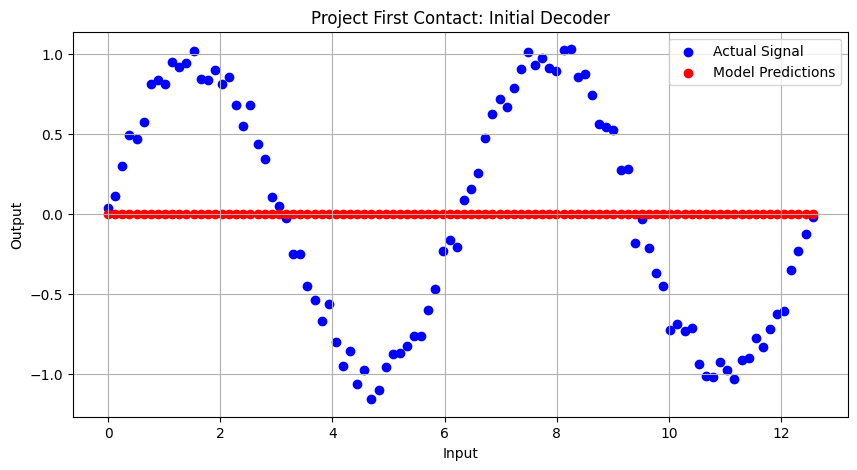

In [ ]:

plt.figure(figsize=(10, 5))

# Actual alien transmission
plt.scatter(x, y, color="blue", label="Actual Signal")

# Model predictions
plt.scatter(x, predictions, color="red", label="Model Predictions")

plt.xlabel("Input")
plt.ylabel("Output")
plt.title("Project First Contact: Initial Decoder")
plt.legend()
plt.grid(True)
plt.show()


In [ ]:

# Calculate the error for each prediction
errors = predictions - y

# Square each error and calculate the average
mse = np.mean(errors ** 2)

print("Mean Squared Error:", mse)


Mean Squared Error: 0.5051630710778223


In [ ]:

def train_model(x, y, learning_rate=0.001, epochs=100):

    # Start with weight and bias at zero
    weight = 0.0
    bias = 0.0

    # Store the model's progress
    mse_history = []
    weight_history = []
    bias_history = []

    n = len(x)

    # Save the starting values
    weight_history.append(weight)
    bias_history.append(bias)

    # Begin training
    for epoch in range(epochs):

        # Calculate predictions
        predictions = weight * x + bias

        # Calculate errors
        errors = predictions - y

        # Calculate Mean Squared Error
        mse = np.mean(errors ** 2)
        mse_history.append(mse)

        # Calculate gradients
        weight_gradient = (2 / n) * np.sum(x * errors)
        bias_gradient = (2 / n) * np.sum(errors)

        # Update weight and bias
        weight = weight - learning_rate * weight_gradient
        bias = bias - learning_rate * bias_gradient

        # Save the updated model parameters
        weight_history.append(weight)
        bias_history.append(bias)

    return weight, bias, mse_history, weight_history, bias_history


In [ ]:

weight, bias, mse_history, weight_history, bias_history = train_model(
    x, y,
    learning_rate=0.001,
    epochs=100
)

print("Final Weight:", weight)
print("Final Bias:", bias)
print("Final MSE:", mse_history[-1])


Final Weight: -0.021557309506292976
Final Bias: 0.01976811716173179
Final MSE: 0.480790872251203


In [ ]:

def plot_mse(mse_history):

    plt.figure(figsize=(10, 5))

    plt.plot(mse_history)

    plt.xlabel("Epoch")
    plt.ylabel("Mean Squared Error (MSE)")
    plt.title("Model Learning: Error Over Time")

    plt.grid(True)
    plt.show()


In [ ]:

def plot_model(x, y, weight, bias):

    # Calculate predictions using the trained model
    predictions = weight * x + bias

    plt.figure(figsize=(10, 5))

    # Plot the actual alien signal
    plt.scatter(x, y, color="blue", label="Actual Signal")

    # Plot the model's predictions
    plt.plot(x, predictions, color="red", label="Linear Model")

    plt.xlabel("Input")
    plt.ylabel("Output")
    plt.title("Project First Contact: Final Decoder")

    plt.legend()
    plt.grid(True)
    plt.show()

    return predictions


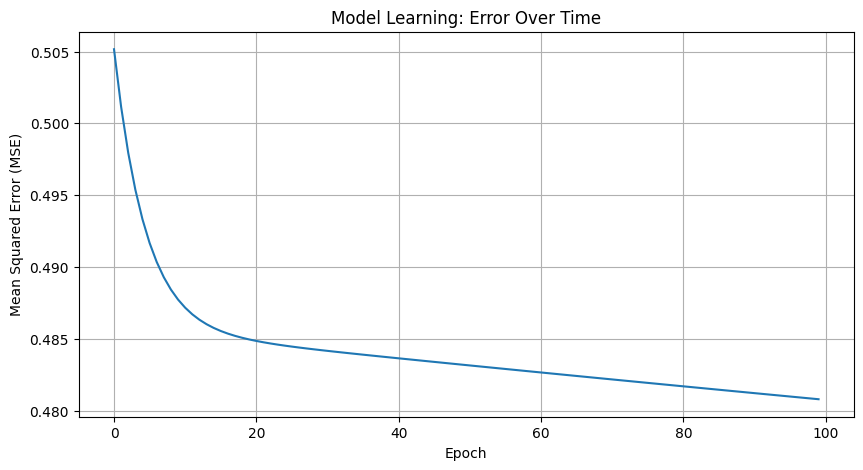

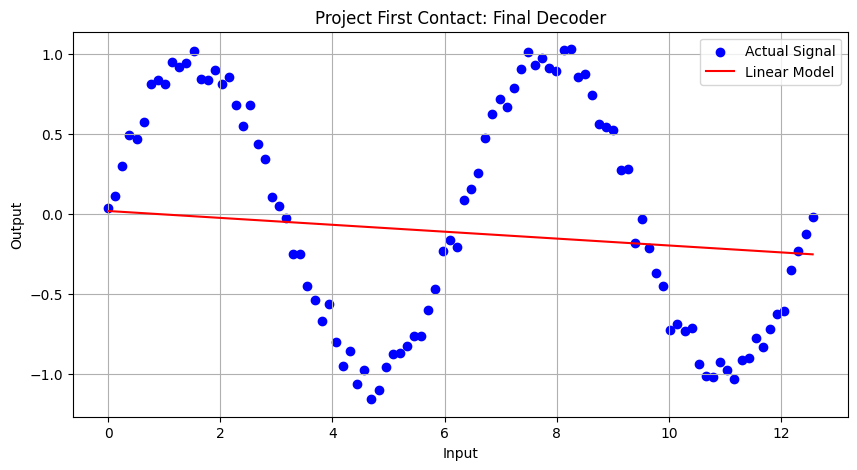

In [ ]:
plot_mse(mse_history)
predictions = plot_model(x, y, weight, bias)

Our linear model with only one neuron can produce a non-linear (curved) output.  We need a more complex model to handle non-linear outputs.  Let's try a neural network with two nodes.

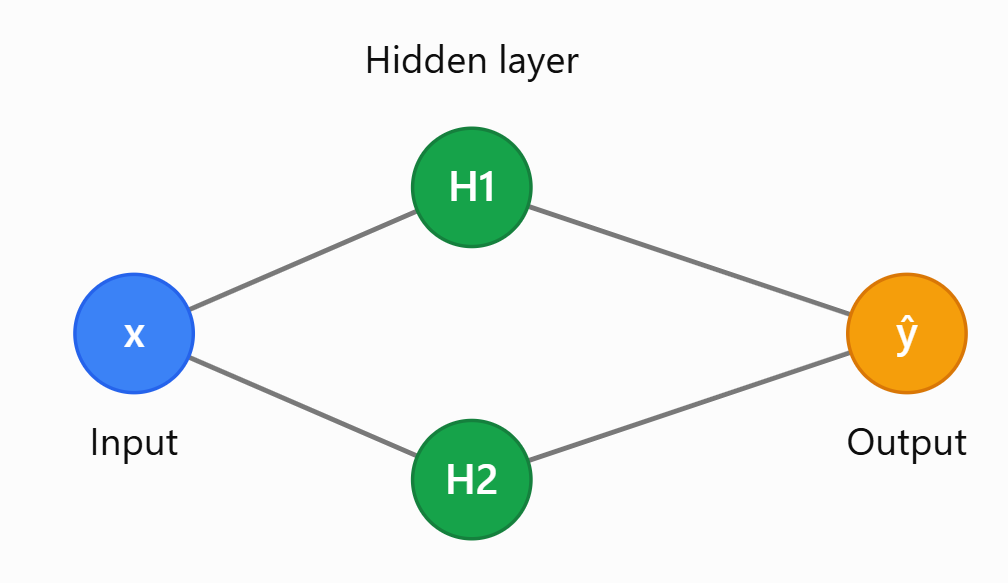

In [ ]:

# Normalize the input values
x_scaled = (x - np.mean(x)) / np.std(x)

# STUDENT-CONTROLLED WEIGHTS AND BIASES

# Hidden neuron 1
w1 = 1.0
b1 = 1.0

# Hidden neuron 2
w2 = -1.0
b2 = 1.0

# Output layer
v1 = 1.0
v2 = 1.0
c = 1.0

# Calculate hidden neuron outputs
h1 = np.tanh(w1 * x_scaled + b1)
h2 = np.tanh(w2 * x_scaled + b2)

# Calculate final predictions
predictions = v1 * h1 + v2 * h2 + c

# Calculate error
mse = np.mean((predictions - y) ** 2)

print("Mean Squared Error:", round(mse, 4))


Mean Squared Error: 4.8339


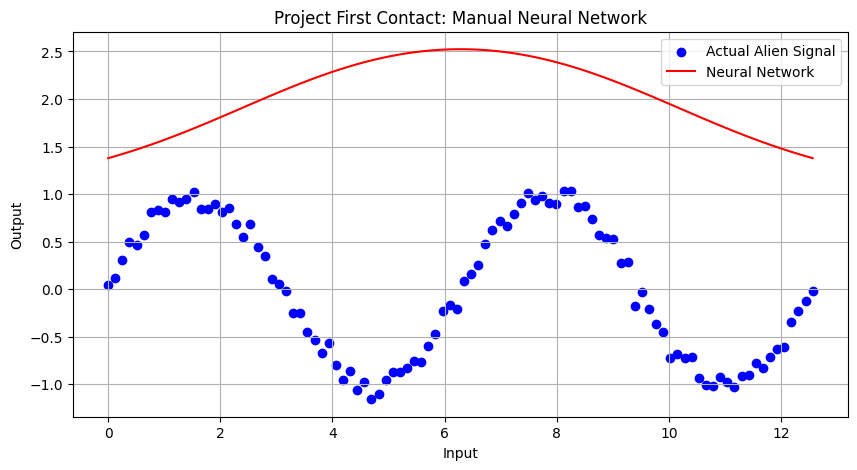

In [ ]:

plt.figure(figsize=(10, 5))

plt.scatter(x, y, color="blue", label="Actual Alien Signal")
plt.plot(x, predictions, color="red", label="Neural Network")

plt.xlabel("Input")
plt.ylabel("Output")
plt.title("Project First Contact: Manual Neural Network")

plt.legend()
plt.grid(True)
plt.show()
